# Random Number Generators

Moreno Marzolla

Last modified: 2026-10-02

---

Given integer parameters $a, c, m$, a Linear Congruential Generator (LCG) is a recurrence equation:

$$
x_n = (ax_{n-1} + c) \mod m
$$

Starting from an initial _seed_ $x_0$, a LCG generates a sequence of integers in $\{0, \ldots, m-1\}$.

We can realize a generic LCG as a Python generator.

In [15]:
def LCG(a, c, m, x0):
    x = x0
    while True:
        yield x
        x = (a*x + c) % m

Foe example, let us consider the recurrence $x_n = (5x_{n-1} +1) \mod 16$. It can be shown that this generator has cycle length 16 (the maximum possible), as we can empirically observe by picking a seed, say $x_0 = 0$.

In [18]:
import itertools as it

r = LCG(5, 1, 16, 0)

print(list(it.islice(r, 32)))

[0, 1, 6, 15, 12, 13, 2, 11, 8, 9, 14, 7, 4, 5, 10, 3, 0, 1, 6, 15, 12, 13, 2, 11, 8, 9, 14, 7, 4, 5, 10, 3]


LCGs are very simple and fast. However, they have a small state space and often are unable to achieve maximum cycle length. 

In [178]:
import numpy as np

N = 10000
# generate N random numbers using Python's random()
rpython = np.random.default_rng(123).random(N)
# generate B random numbers using LCG(3, 0, 31)
#a, c, m, x0 = 3, 0, 31, 1
a, c, m, x0 = 65539, 0, 2**31, 17
rlcg = list(it.islice(LCG(a, c, m, x0), N))

Perform the spectral test.

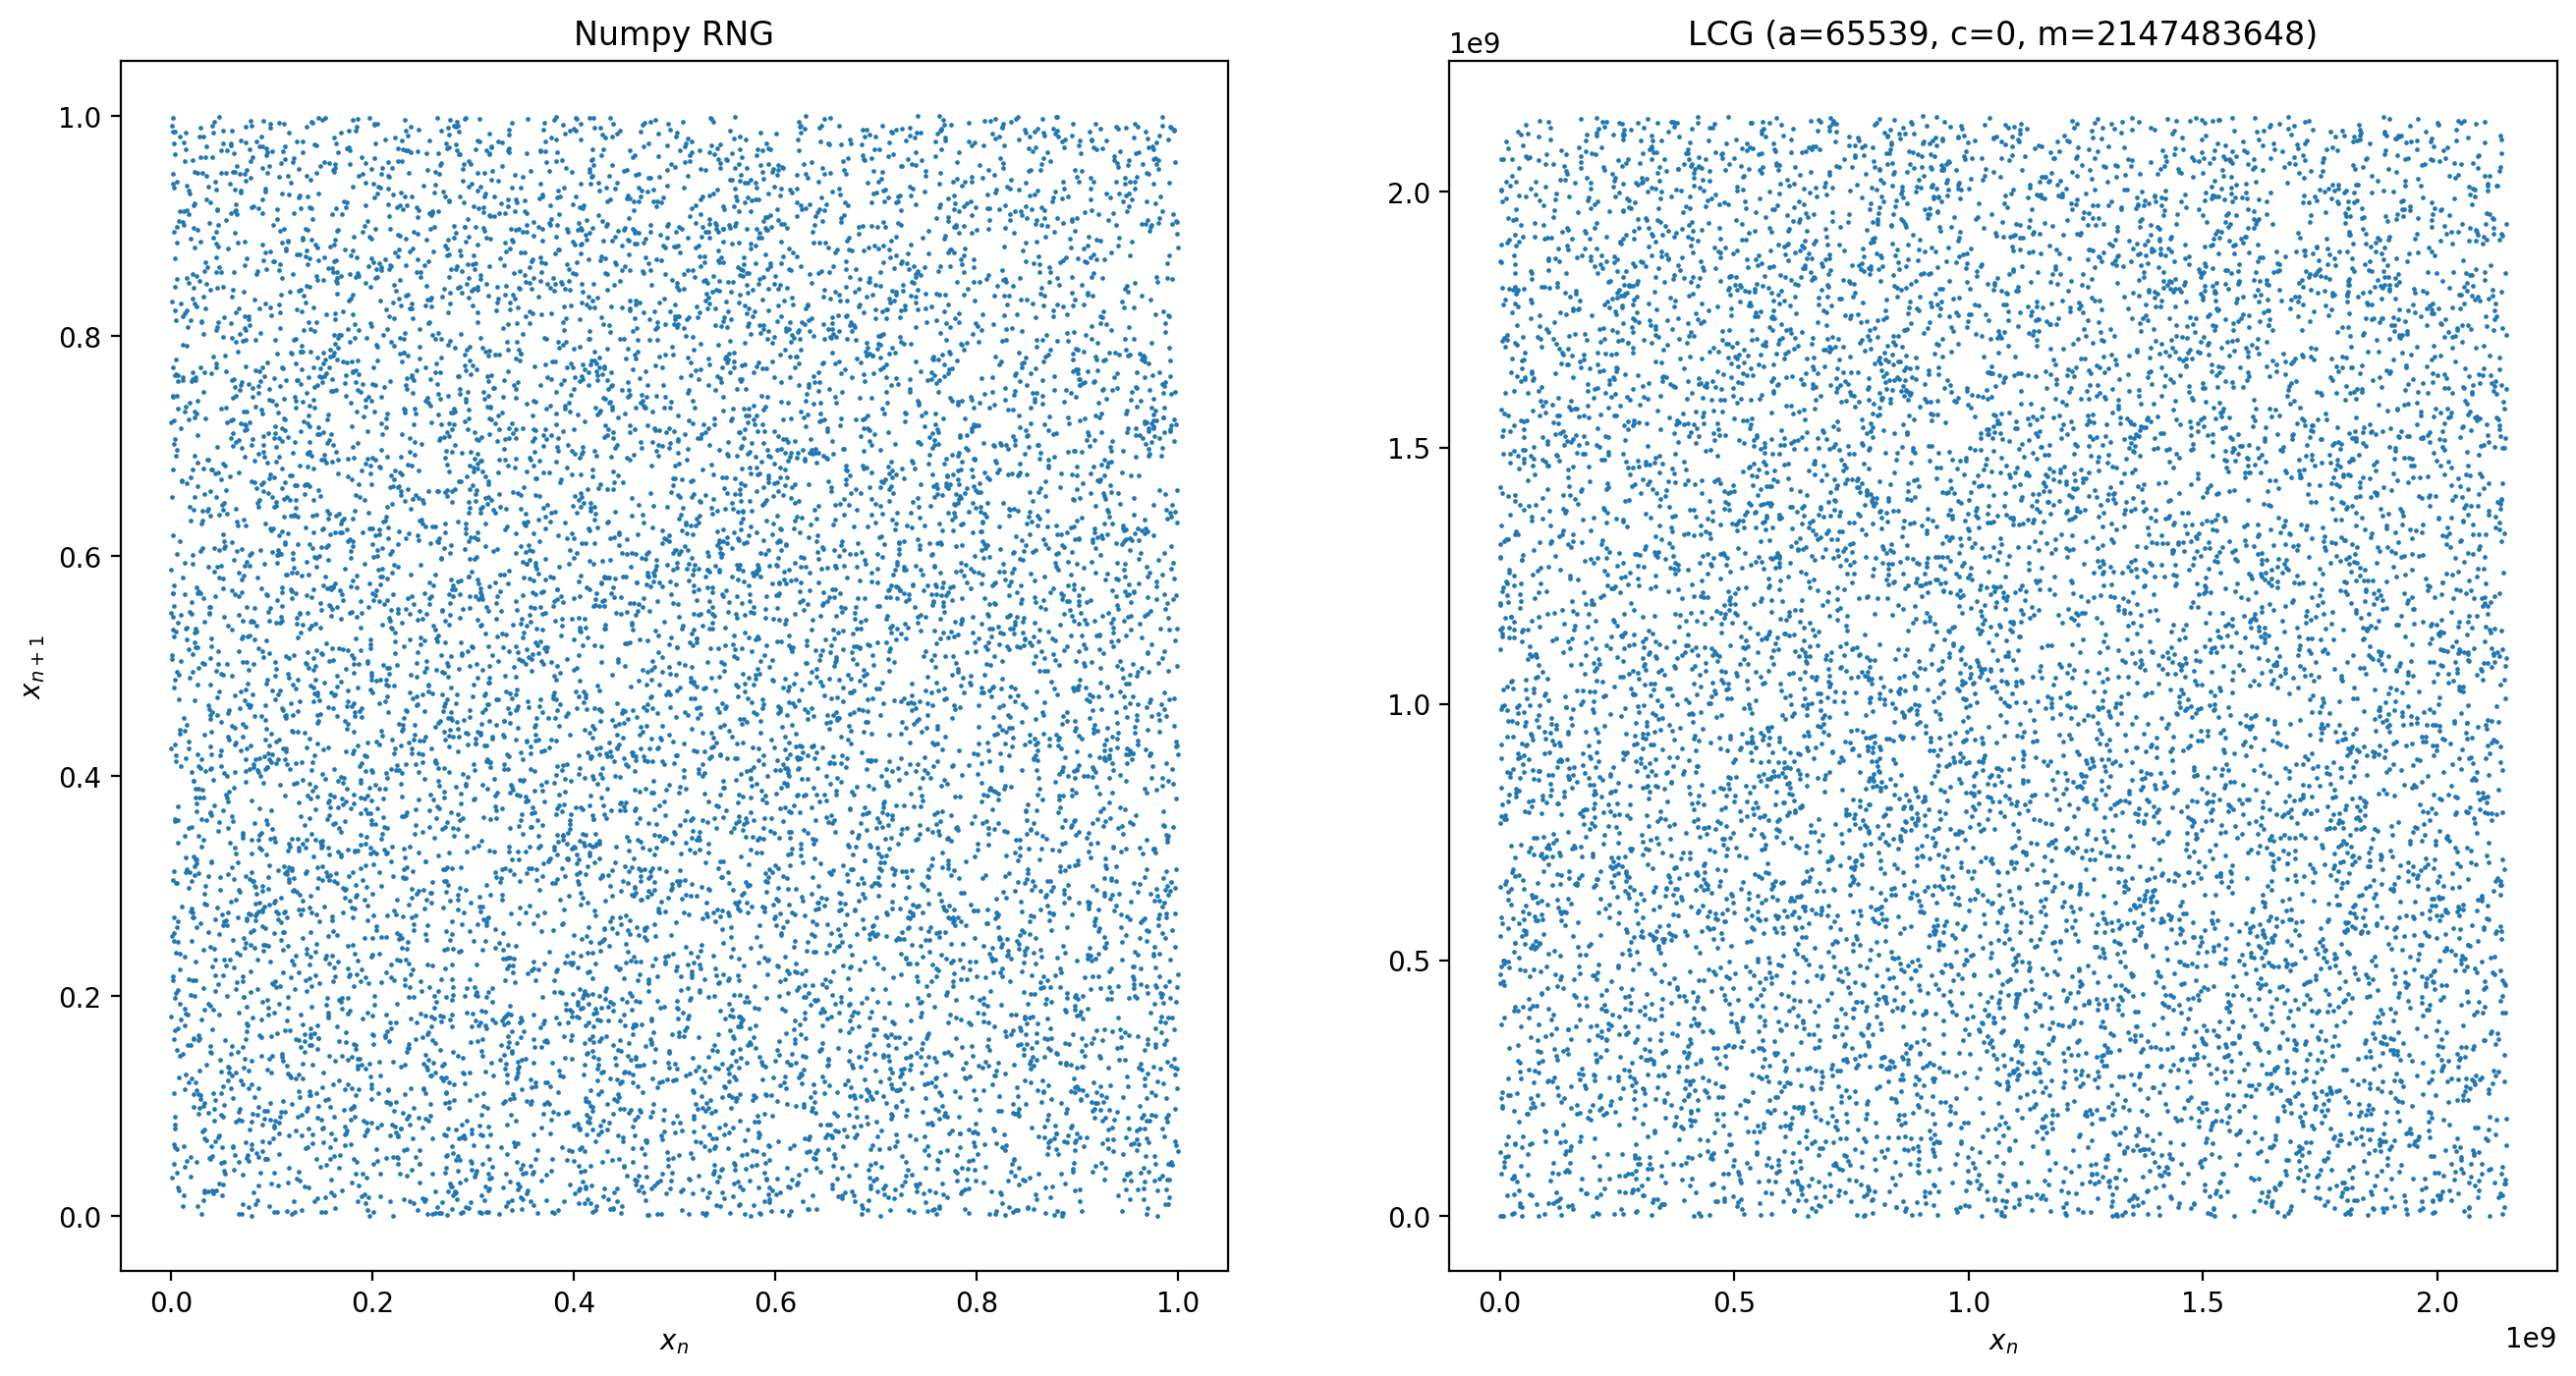

In [182]:
from matplotlib import pyplot as plt
plt.rcParams['figure.dpi'] = 200

plt.subplots(1, 2, figsize=(16,8))

plt.subplot(1,2,1)
plt.scatter(rpython[1:], rpython[:-1], s=0.5)
plt.title("Numpy RNG")
plt.xlabel("$x_n$")
plt.ylabel("$x_{n+1}$")

plt.subplot(1,2,2)
plt.scatter(rlcg[1:], rlcg[:-1], s=0.5)
plt.title(f"LCG (a={a}, c={c}, m={m})")
plt.xlabel("$x_n$")

plt.show()

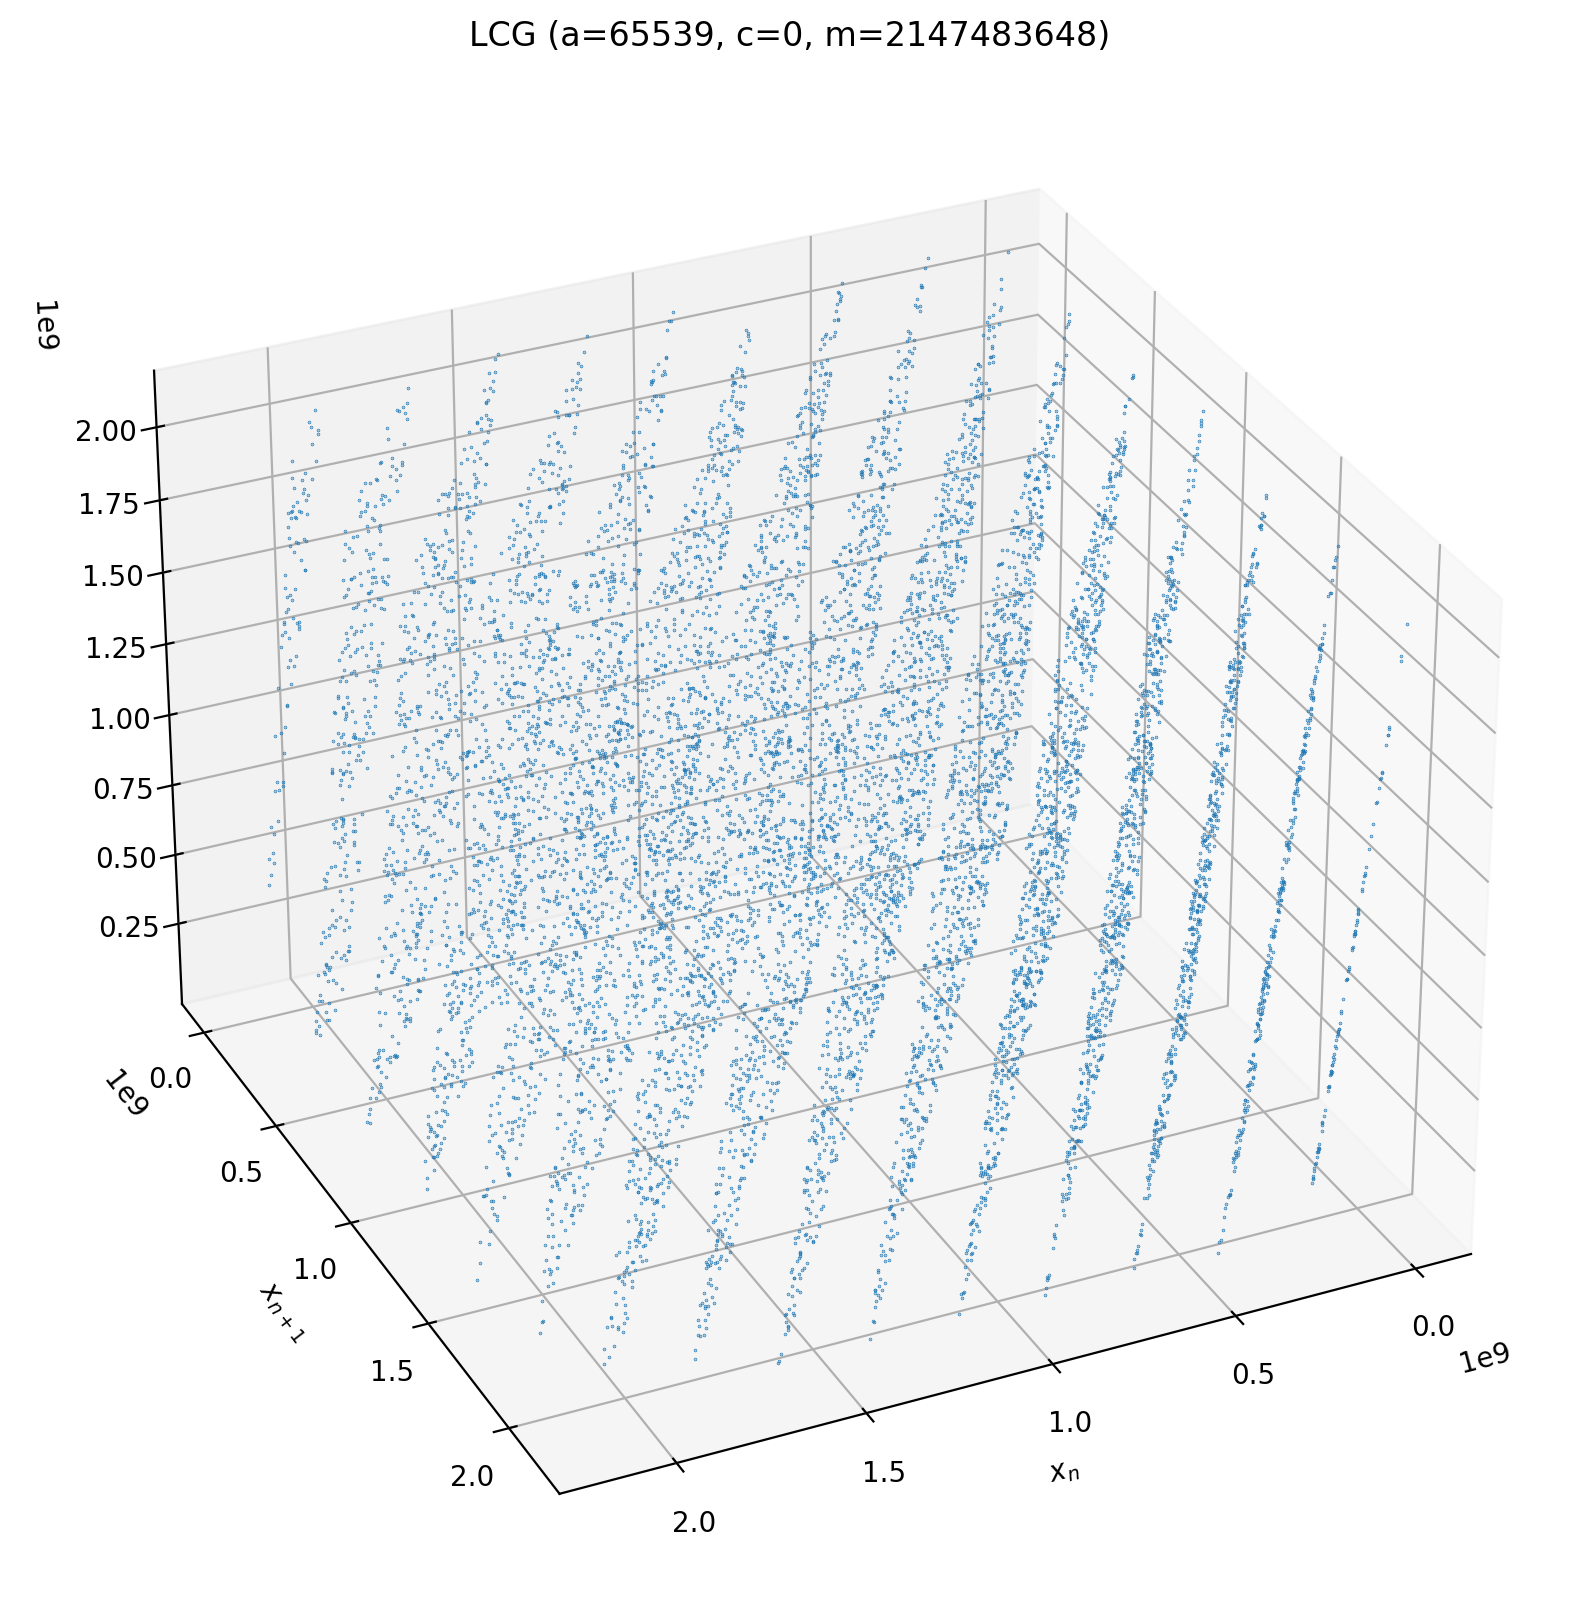

In [183]:
ax = plt.figure(figsize=(10,10)).add_subplot(projection="3d")
plt.plot(rlcg[:-2], rlcg[1:-1], rlcg[2:], '.', markersize=0.5)
#ax.view_init(azim=65)
plt.title(f"LCG (a={a}, c={c}, m={m})")
plt.xlabel("$x_n$")
plt.ylabel("$x_{n+1}$")
plt.show()